# 3. A legged robot on a battery: what the policy must observe, the price, and a reserve margin

A robot runs forward (MuJoCo's HalfCheetah) on a mission of 1000 steps. It now carries a battery: each step draws an
idle load plus the resistive losses of its motors, which grow with the square of the torques, scaled by an
efficiency that varies from mission to mission with battery health and temperature and is not observed. A robot
whose battery runs flat before the end of the mission is stranded. Running fast earns the most per step and drains
the battery fastest.

The notebook builds the problem and trains it in the open, following the steps of the
[practitioner guide](../docs/practitioner-guide.md):

1. add the battery to the task, and define the problem as a budget;
2. decide what the policy must observe: the charge left and the time left;
3. check the wrapped task, and train PPO;
4. compare prices in the full campaign;
5. test a reserve margin against a battery that holds less than the robot believes;
6. validate and report.

Notes marked **Theory** say what the results behind the method imply at each step. The training here is short; the
comparisons use the full campaign in `campaigns/` (2 million steps per run, three seeds), which ran this same code.
It needs Gymnasium with MuJoCo (`pip install "gymnasium[mujoco]"`) and Stable-Baselines3.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize

from bpg import BudgetSpec, Requirement, Stage, BudgetWrapper, evaluate, interpret
from bpg.callbacks import BudgetMonitor

sys.path.insert(0, str(Path("..").resolve() / "campaigns"))
from records import Campaign                     # the records of the full campaign
camp = Campaign("robot")
torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## 1. Define the problem as a budget

### The resource: a battery added to the task

The task has no battery, so a small Gymnasium wrapper adds one: it draws an efficiency for each mission and reports
the energy of every step in `info`. The cost function then reads it.

In [2]:
class Battery(gym.Wrapper):
    """HalfCheetah with a battery draw in info['energy']: (idle load + squared torques) times the mission's efficiency."""

    def __init__(self, idle=0.5, efficiency_sd=0.15, mission=1000):
        super().__init__(gym.make("HalfCheetah-v5", max_episode_steps=mission))
        self.idle, self.sd = idle, efficiency_sd
        self.rng = np.random.default_rng()

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            self.rng = np.random.default_rng([int(seed), 0x62617474])
        self.efficiency = float(np.exp(self.sd * self.rng.standard_normal() - 0.5 * self.sd ** 2))   # mean one
        return self.env.reset(seed=seed, options=options)

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        a = np.clip(np.asarray(action, dtype=float), -1.0, 1.0)
        info = dict(info, energy=self.efficiency * (self.idle + float(a @ a)), efficiency=self.efficiency)
        return obs, reward, terminated, truncated, info


def energy_used(obs, action, next_obs, reward, info):
    return [info["energy"]]

### The budget, the requirement and the price

* `budgets`: a battery of 2,500 units. A gait trained without a battery uses about 3,100 per mission (section 3).
* `horizon`: the mission, 1000 steps; `beta = 0.999`, so that a late stranding is not cheap.
* `ubar`, `u_minus`: bounds on the task's reward per step (forward speed minus a small control charge), taken as 20
  and 21; only the certificates use them.
* The requirement: stranded in at most 5% of missions, shown at 95% confidence, the error shared among ten candidates.
* The price: `Stage(m=3, clip_utility=False)`. The task's reward is negative when the robot runs backwards, and
  clipping it at `-m` would change the task; only the failure is priced.

In [3]:
spec = BudgetSpec(budgets=[2500.0], beta=0.999, ubar=20.0, u_minus=21.0, horizon=1000)
req = Requirement(T=spec.horizon - 1, alpha=0.05, zeta=0.05, family=10)
stage = Stage(m=3.0, clip_utility=False)

## 2. What the policy must observe

The policy has to pace the battery, and pacing needs two inputs: how much charge is left and how much of the mission
is left. The wrapper appends the remaining charge, and with `observe_time=True` also the elapsed fraction of the
mission; the task's own observation has no clock.

**Theory.** The results are stated for policies that act on the state of the problem. With a fixed horizon, the time
left is part of that state: whether a given charge suffices depends on it. A policy that cannot see the time solves
a different, harder problem, and no price makes up for it.

In [4]:
def make_env(stage, observe_time=True, **options):
    return BudgetWrapper(Battery(), energy_used, spec, stage, observe_time=observe_time, **options)


print(Campaign.show(camp.table(["unpriced-no-clock", "unpriced", "price-3-no-clock", "price-3"], extras=("distance",)), extras=("distance",)))

configuration    seeds        failure (min-max)          utility (min-max)     distance
unpriced-no-clock     3  63.733% (52.60%-71.20%)           2758 (2624-2960)    [223.106]
unpriced             3  20.400% (17.60%-24.00%)           2717 (2637-2786)    [226.668]
price-3-no-clock     3  32.800% (13.40%-47.20%)           2482 (2033-2764)    [205.009]
price-3              3   10.400% (8.60%-13.40%)           2356 (1781-2688)    [196.803]


The campaign trained the robot with and without the clock. Without it, the robot is stranded in more than half of its
missions when there is no price, and a price helps only in some seeds. With the clock, stranding without a price falls
to about a fifth. With a fixed horizon, observe the time.

## 3. Check the wrapped task, and train

Full torque on every motor draws about 6.5 units per step, so at average efficiency the battery runs flat after about
380 steps; the
failing step should receive the price's charge. The last two entries of the observation are the charge and the time.

In [5]:
env = make_env(stage)
obs, _ = env.reset(seed=0)
for t in range(1000):
    obs, reward, terminated, truncated, info = env.step(np.ones(6, dtype=np.float32))
    if terminated or truncated:
        break
print(f"ran flat at step {info['t']} (efficiency {info['efficiency']:.2f}): failure = {info['failure']}, reward = {reward:.0f}; "
      f"charge and time observed: {np.round(obs[-2:], 3)}")

ran flat at step 408 (efficiency 0.94): failure = True, reward = -1341; charge and time observed: [0.    0.409]


The training function builds eight wrapped tasks, normalizes the observations and the reward scale, and records the
stranding rate and the reward of every batch with `BudgetMonitor`.

**Theory.** The learner's discount `gamma` must be the problem's `beta`. Normalizing observations changes the inputs
the network sees, so the normalization statistics are part of the policy: save them with it (the campaign does) and
apply them whenever the policy acts.

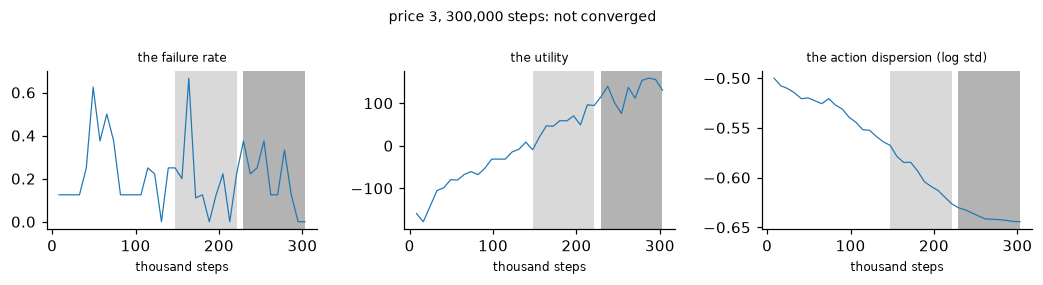

Training convergence over the last 10 batches, compared with the 10 before: not converged.
  the failure rate: stable (0.1922 then 0.1931)
  the utility: still rising (53.04 then 127.8, a change of 59%)
  the priced objective: still rising (4.887 then 70.57, a change of 93%)
  the action dispersion (log std): still falling (-0.598 then -0.6395, a change of 6%)
Train longer before comparing this run with others or deploying its policy; a policy taken from a run that is still changing is the policy at the end of the run, and it should be validated as such.

last five batches: stranded 11.7%, discounted reward 142


In [6]:
PPO_SETTINGS = dict(n_steps=1024, batch_size=256, n_epochs=10, learning_rate=lambda p: 3e-4 * p, gamma=spec.beta,
                    gae_lambda=0.95, clip_range=0.2, ent_coef=0.0, device="cpu", verbose=0,
                    policy_kwargs=dict(net_arch=[64, 64], log_std_init=-0.5))


def train(stage, steps, seed=1, **env_options):
    venv = DummyVecEnv([lambda: make_env(stage, **env_options) for _ in range(8)])
    venv.seed(seed)
    venv = VecNormalize(venv, norm_obs=True, norm_reward=True, clip_obs=1e3, clip_reward=1e9, gamma=spec.beta)
    model = PPO("MlpPolicy", venv, seed=seed, **PPO_SETTINGS)
    monitor = BudgetMonitor(spec.beta, stage.m, horizon=spec.horizon)
    model.learn(steps, callback=[monitor])
    return model, venv, monitor


model, venv, monitor = train(stage, 300_000)
monitor.plot(title="price 3, 300,000 steps"); plt.show()
print(monitor.convergence().explain())
last = monitor.trace[-5:]
print(f"\nlast five batches: stranded {np.mean([t['failure_rate'] for t in last]):.1%}, "
      f"discounted reward {np.mean([t['U'] for t in last]):.0f}")

A short run, and the convergence check says so: after three hundred thousand steps the robot has barely learned to
move forward. Its reward is a small fraction of the campaign's policies' (about 2,400 after 2 million
steps), and it is already stranded in some missions. The campaign ran the same function for 2
million steps, at prices of 0, 1, 3 and 10 per step from the stranding to the end of the mission, and also trained a
gait without a battery (a battery that never runs flat). That gait uses more energy than the battery holds:

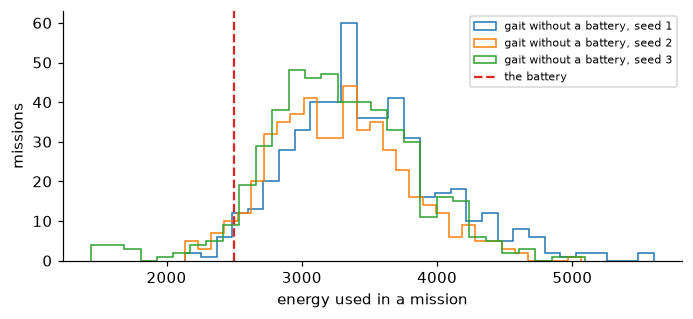

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for s in camp.seeds("no-battery"):
    ax.hist(camp.record("no-battery", s)["evaluation"]["energy"], bins=30, histtype="step", label=f"gait without a battery, seed {s}")
ax.axvline(spec.budgets[0], color="C3", ls="--", label="the battery")
ax.set_xlabel("energy used in a mission"); ax.set_ylabel("missions"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4. The full campaign: prices

In [8]:
prices = ["unpriced", "price-1", "price-3", "price-10"]
print(Campaign.show(camp.table(prices, extras=("distance", "energy")), extras=("distance", "energy")))

print("\nConvergence at the end of training (the toolbox's check on each run's record):")
print(camp.convergence_table(prices + ["barrier"]))

configuration    seeds        failure (min-max)          utility (min-max)     distance       energy
unpriced             3  20.400% (17.60%-24.00%)           2717 (2637-2786)    [226.668]   [2212.145]
price-1              3  16.800% (16.00%-17.60%)           2432 (1824-2779)    [204.585]   [2185.089]
price-3              3   10.400% (8.60%-13.40%)           2356 (1781-2688)    [196.803]   [2093.093]
price-10             3     0.467% (0.00%-1.40%)           1957 (1560-2162)    [163.733]   [1691.245]

Convergence at the end of training (the toolbox's check on each run's record):
unpriced             converged in 2 of 3 seeds  (still changing: seed 2: failure rate)
price-1              converged in 2 of 3 seeds  (still changing: seed 2: failure rate)
price-3              converged in 2 of 3 seeds  (still changing: seed 2: utility, priced objective)
price-10             converged in 2 of 3 seeds  (still changing: seed 2: utility, priced objective)
barrier              converged in 3 of 3 

Stranding falls steadily with the price, and so does the distance covered: pacing the battery means running slower.
Only the price of 10 meets the 5% tolerance in every seed. Most runs had converged by the end of training; in most
configurations one seed was still changing, and its policy is the policy at the end of the run.

**Theory.** The price chooses a point on the trade-off between distance and the risk of stranding: each trained
policy is, up to the learner's shortfall, the best among those stranded no more often than it is. The tolerance
decides which price is enough; training at a few prices and validating each finds it.

## 5. A reserve margin against a weaker battery

Every configuration was also evaluated with a battery that holds 10% less than the robot believes: the wrapper's
`true_budget_scale=0.9` judges failure against the smaller battery while the robot sees the nominal charge. The
campaign also trained an interior barrier at the price 3, `Stage(m=3, theta=0.5, clip_utility=False)`, which charges
a small amount every step that grows as the charge falls.

**Theory.** A price on failure alone produces policies that use the budget up whenever that pays, with no reserve.
The interior barrier keeps a graded reserve at a cost bounded by its interior loss. If the size of the error is
known, planning with the smaller budget is cheaper.

In [9]:
for cfg in ["unpriced", "price-1", "price-3", "price-10", "barrier"]:
    nominal = [np.mean(r["evaluation"]["failed"]) for r in camp.records(cfg)]
    weak = [np.mean(r["extra_evaluations"][0]["episodes"]["failed"]) for r in camp.records(cfg)]
    dist = [np.mean(r["evaluation"]["distance"]) for r in camp.records(cfg)]
    print(f"{cfg:10s} stranded: nominal battery {np.mean(nominal):6.1%}, battery 10% weaker {np.mean(weak):6.1%};  distance {np.mean(dist):6.0f}")

unpriced   stranded: nominal battery  20.4%, battery 10% weaker  49.3%;  distance    227
price-1    stranded: nominal battery  16.8%, battery 10% weaker  45.3%;  distance    205
price-3    stranded: nominal battery  10.4%, battery 10% weaker  30.7%;  distance    197
price-10   stranded: nominal battery   0.5%, battery 10% weaker   2.1%;  distance    164
barrier    stranded: nominal battery   7.1%, battery 10% weaker  20.2%;  distance    168


With a battery that holds 10% less, every policy is stranded more often. A policy that meets the tolerance with room
to spare (the price of 10) keeps a margin under the weaker battery as well. The interior barrier at a lower price (3)
lowered stranding in two of three seeds, under both batteries, but its results varied widely across seeds; on this
problem a higher price was the more reliable way to a reserve.

## 6. Validate and report

We validate the candidate with the least stranding on its first evaluation, on 500 fresh missions, as a stochastic
policy and as its mean action; `camp.policy` applies the observation statistics saved with it. Ten candidates were
inspected, so the error is shared among ten.

In [10]:
cands = [(c, s) for c in prices + ["barrier"] for s in camp.seeds(c)]
best = min(cands, key=lambda cs: np.mean(camp.record(*cs)["evaluation"]["failed"]))
print("candidate:", best, camp.record(*best)["note"])
best_stage = camp.stage(*best)
for det in (False, True):
    e = evaluate(lambda: make_env(best_stage), camp.policy(*best, deterministic=det), 500, spec=spec, stage=best_stage,
                 T=req.T, seed=555)
    name = f"the {'mean action of the' if det else 'stochastic'} policy {best[0]}, seed {best[1]}"
    print()
    print(interpret(spec, req, best_stage, e, candidate_name=name).summary(resource="charge", period="steps"))

candidate: ('price-10', 2) battery, price 10



The stochastic policy price-10, seed 2 was run on 500 fresh episodes. It ran out of charge within 1000 steps in 0 of them (0.00%).
With confidence 0.95, its probability of running out within 1000 steps is at most 1.054% (the error 0.05 is shared among 10 candidates).
Requirement (at most 5.00%): met.
Utility per episode: 1564 (standard error 3.7).
Episodes that came within 5% of running out, or ran out: 0.4%.

What this test does not show:
  - that the policy is the best possible at this risk: how far training fell short of the optimum is not measured;
  - its risk over more than 1000 steps, or that of other policies (its mean action, a retrained network);
  - its behavior outside the simulator.
Every bound with its assumptions: report.text().



The mean action of the policy price-10, seed 2 was run on 500 fresh episodes. It ran out of charge within 1000 steps in 0 of them (0.00%).
With confidence 0.95, its probability of running out within 1000 steps is at most 1.054% (the error 0.05 is shared among 10 candidates).
Requirement (at most 5.00%): met.
Utility per episode: 1903 (standard error 1.2).
Episodes that came within 5% of running out, or ran out: 0.0%.

What this test does not show:
  - that the policy is the best possible at this risk: how far training fell short of the optimum is not measured;
  - its risk over more than 1000 steps, or that of other policies (its mean action, a retrained network);
  - its behavior outside the simulator.
Every bound with its assumptions: report.text().


Both pass. The mean action covers more distance with no more stranding: it spends no effort on the noise that the
stochastic policy adds to its actions. If you deploy the mean action, it is the candidate whose validation counts.

## Regularizers

The robot learns from scratch, and nothing trusted is available. The gait trained without a battery is a policy the new
requirement rejects: it uses more energy than the battery holds, and anchoring to it would keep that, as the lander's
parameter anchor kept its controller's flaw. So the campaign used no regularizer. If you have a reference policy you
trust (a gait that respects the battery, say), the code of notebook 1 applies unchanged: start from it, and add
`ParameterAnchor(model, kappa_p).install()` or an `ActionAnchor(eta, log_reference)` callback to `train`.

## Your own task

The cells to change for a task of your own: the wrapper that adds the resource to the task (`Battery`), the cost
function (`energy_used`), `spec`, `req` and `stage`, and `make_env`, keeping `observe_time=True` when the horizon is
fixed and the task does not observe the time. `python campaigns/run.py robot price-3 --seed 4` reruns one
configuration of the campaign.